# Seeing the limitations of the binary fitting algorithm by seeing where a third star produces an unrecoverable fit

In [57]:
# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import argparse

import pandas as pd
from tqdm import tqdm

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice
from PhotonicLanternFitting import PhotonicLanternFitting

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

## Loading in survey results

In [58]:
loaded_data = np.load('datafiles/triple_survey_linear.npz')

r2s = loaded_data['r2s']
theta2s = loaded_data['theta2s']
x3s = loaded_data['x3s']
y3s = loaded_data['y3s']
F3_crit = loaded_data['F3_crit']
limiting_param = loaded_data['limiting_param']
F3_detect = loaded_data['F3_detect']
sigmas = loaded_data['sigmas']
param_names = loaded_data['param_names']
K_SIGMA = loaded_data['K_SIGMA']
K_DETECT = loaded_data['K_DETECT']
NOISE = loaded_data['NOISE']

## Plotting the results for a given $r_2$ and $\theta_2$

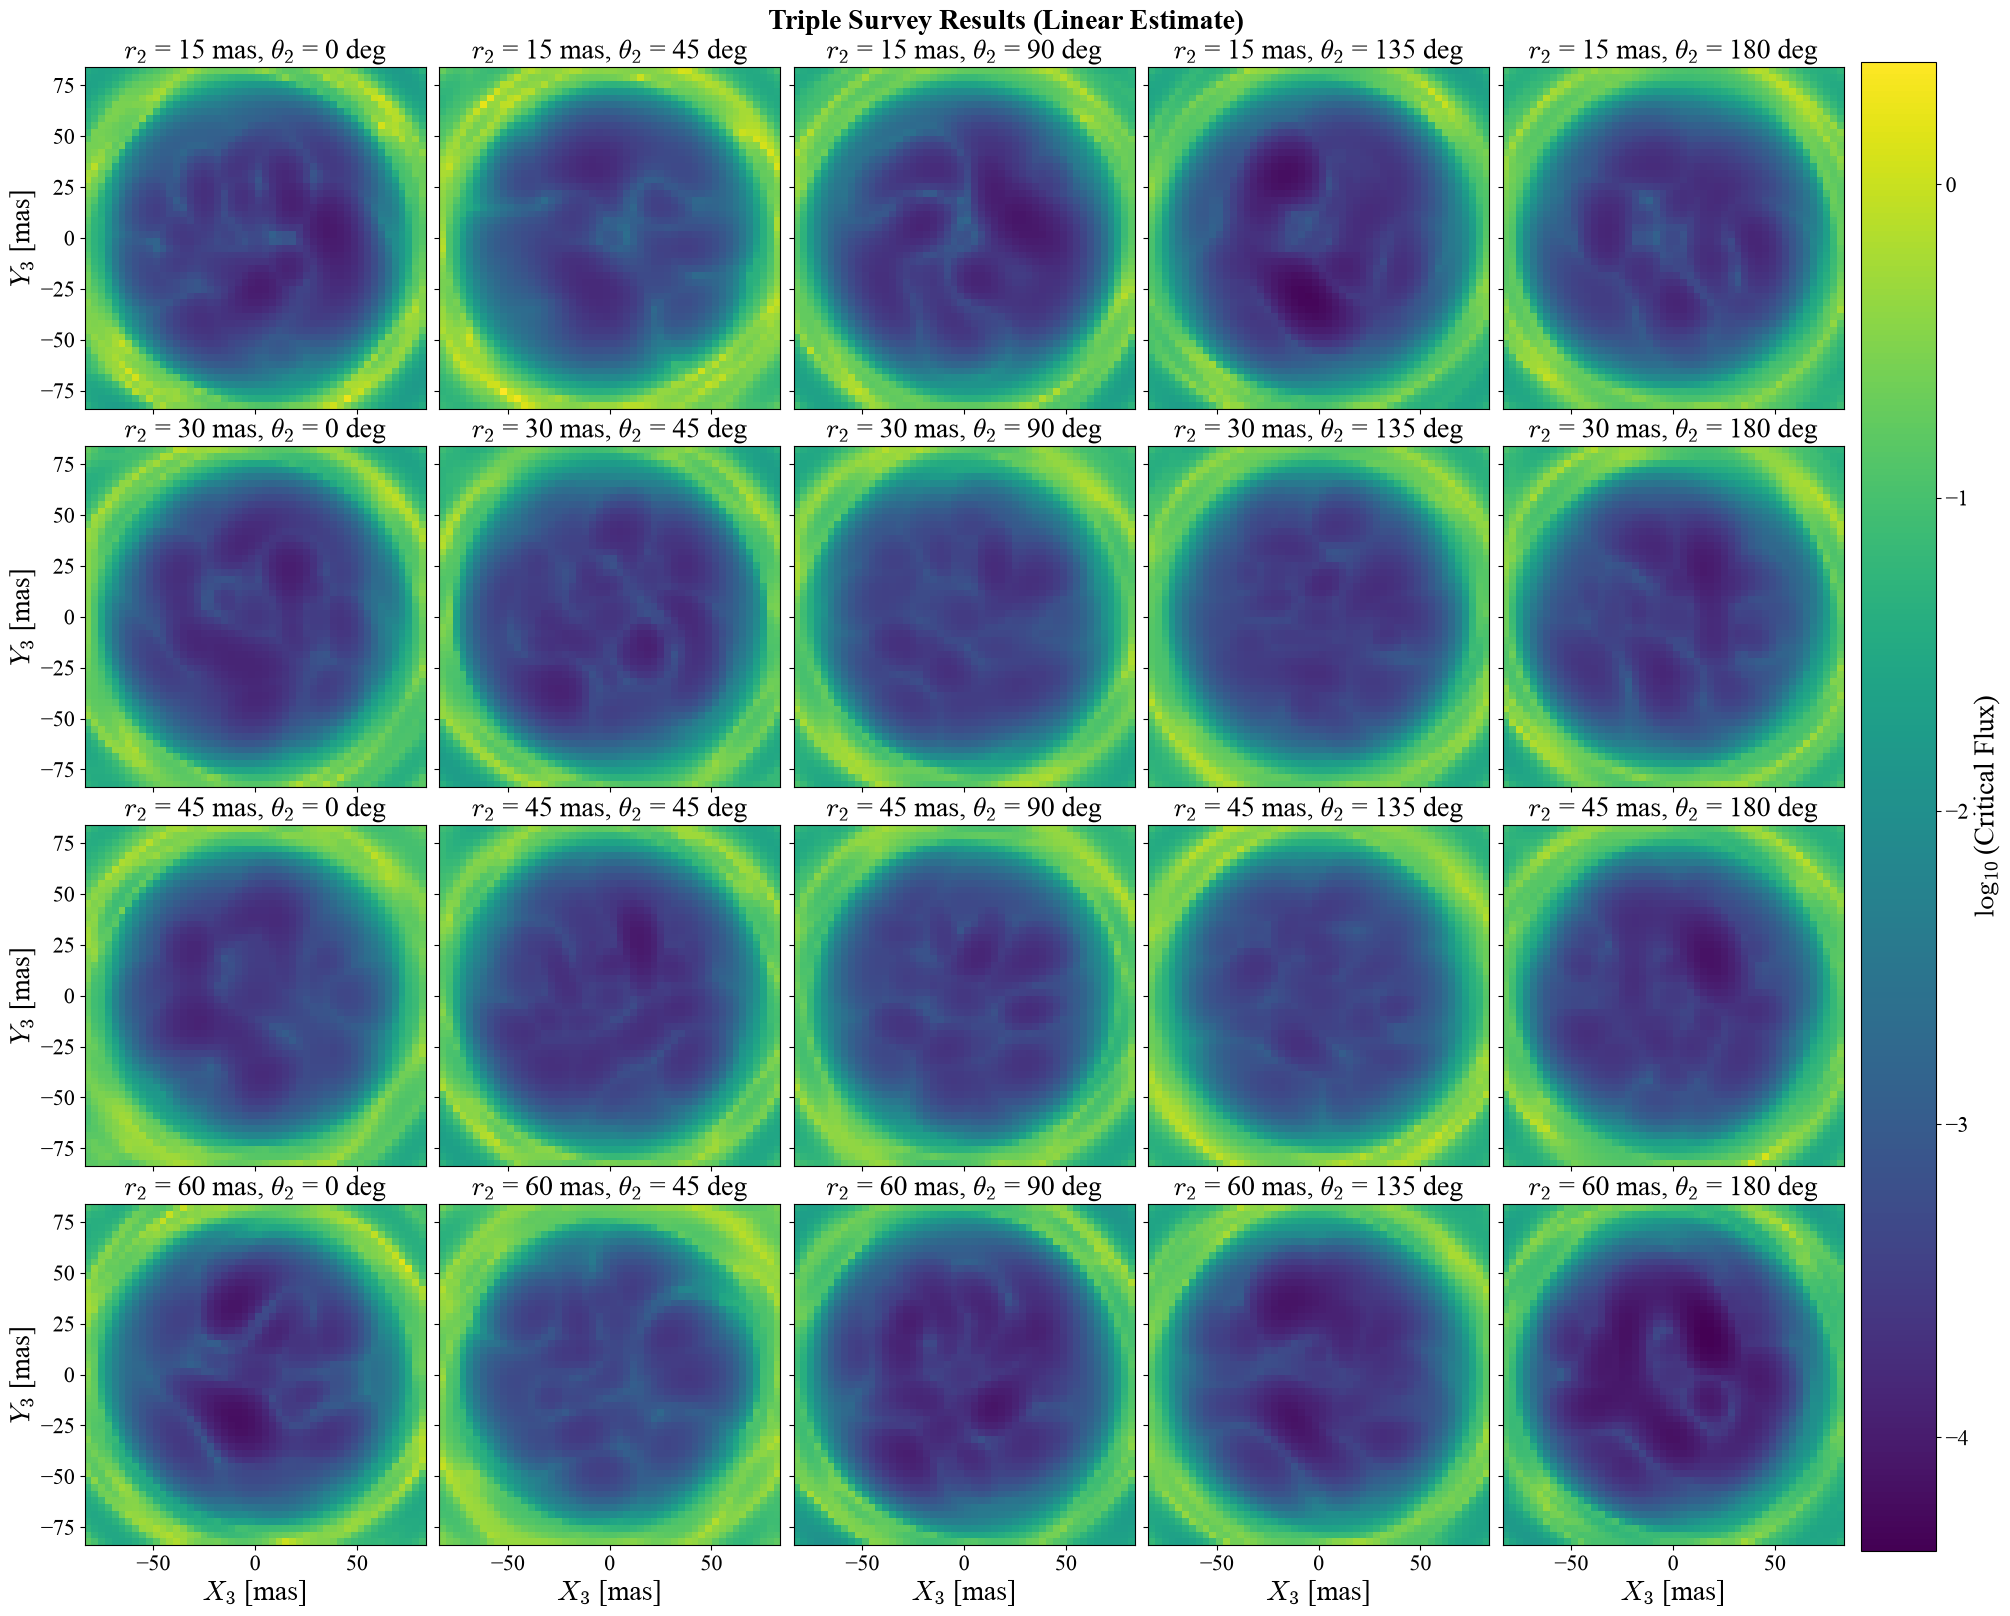

In [ ]:
fig = plt.figure(figsize=(20, 16))
fig.set_constrained_layout(True)
axes = fig.subplots(4, 5, sharex=True, sharey=True)

fig.suptitle('Triple Survey Results (Linear Estimate)')

F3_crit_log10 = np.log10(F3_crit)
F3_crit_log10_min = F3_crit_log10.min()
F3_crit_log10_max = F3_crit_log10.max()

for i, r2 in enumerate(r2s):
    for j, theta2 in enumerate(theta2s):
        ax = axes[i, j]

        ax.set_title(f'$r_2$ = {r2} mas, $\\theta_2$ = {theta2} deg')

        img = ax.imshow(F3_crit_log10[i, j], cmap='viridis', origin='lower', extent=[x3s.min(), x3s.max(), y3s.min(), y3s.max()], vmin=F3_crit_log10_min, vmax=F3_crit_log10_max)
        
        if j == 0:
            ax.set_ylabel('$Y_3$ [mas]')
        if i == 3:
            ax.set_xlabel('$X_3$ [mas]')

fig.colorbar(img, ax=axes, location='right', label=r'$\log_{10}$(Critical Flux)', pad=0.01)

plt.show()

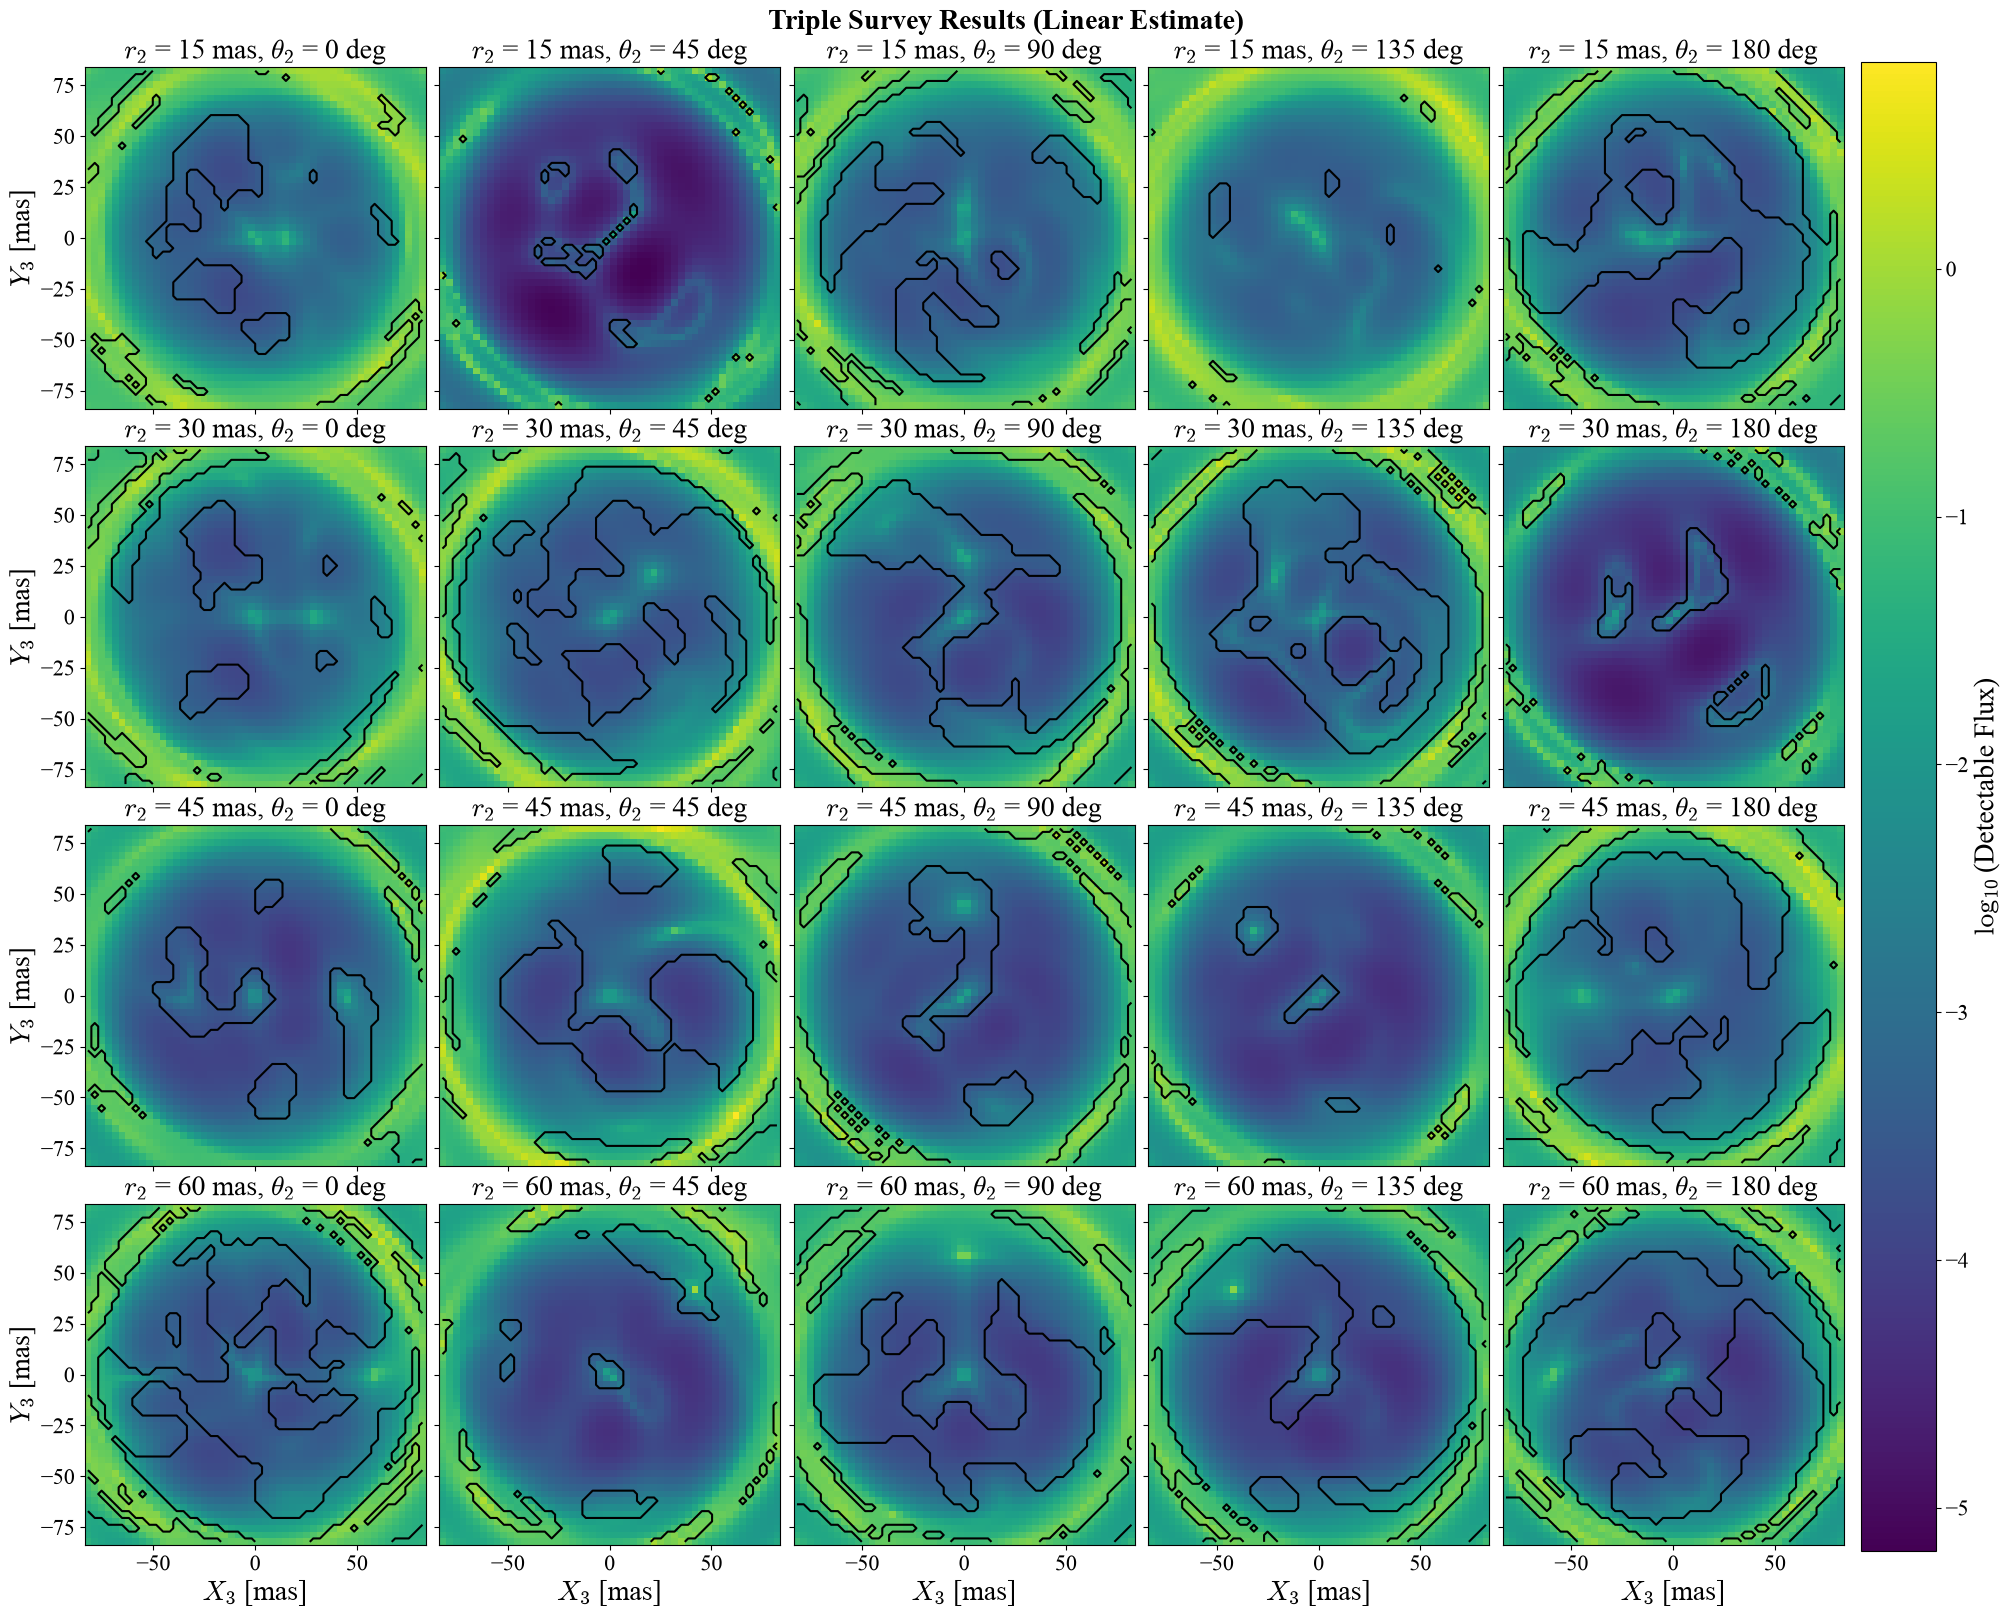

In [60]:
fig = plt.figure(figsize=(20, 16))
fig.set_constrained_layout(True)
axes = fig.subplots(4, 5, sharex=True, sharey=True)

fig.suptitle('Triple Survey Results (Linear Estimate)')

F3_detect_log10 = np.log10(F3_detect)
F3_detect_log10_min = F3_detect_log10.min()
F3_detect_log10_max = F3_detect_log10.max()

biased_region = F3_detect > F3_crit

for i, r2 in enumerate(r2s):
    for j, theta2 in enumerate(theta2s):
        ax = axes[i, j]

        ax.set_title(f'$r_2$ = {r2} mas, $\\theta_2$ = {theta2} deg')

        img = ax.imshow(F3_detect_log10[i, j], cmap='viridis', origin='lower', extent=[x3s.min(), x3s.max(), y3s.min(), y3s.max()], vmin=F3_detect_log10_min, vmax=F3_detect_log10_max)
        ax.contour(biased_region[i, j], colors='black', origin='lower', extent=[x3s.min(), x3s.max(), y3s.min(), y3s.max()], levels=[0.5])
        
        if j == 0:
            ax.set_ylabel('$Y_3$ [mas]')
        if i == 3:
            ax.set_xlabel('$X_3$ [mas]')

fig.colorbar(img, ax=axes, location='right', label=r'$\log_{10}$(Detectable Flux)', pad=0.01)

plt.show()

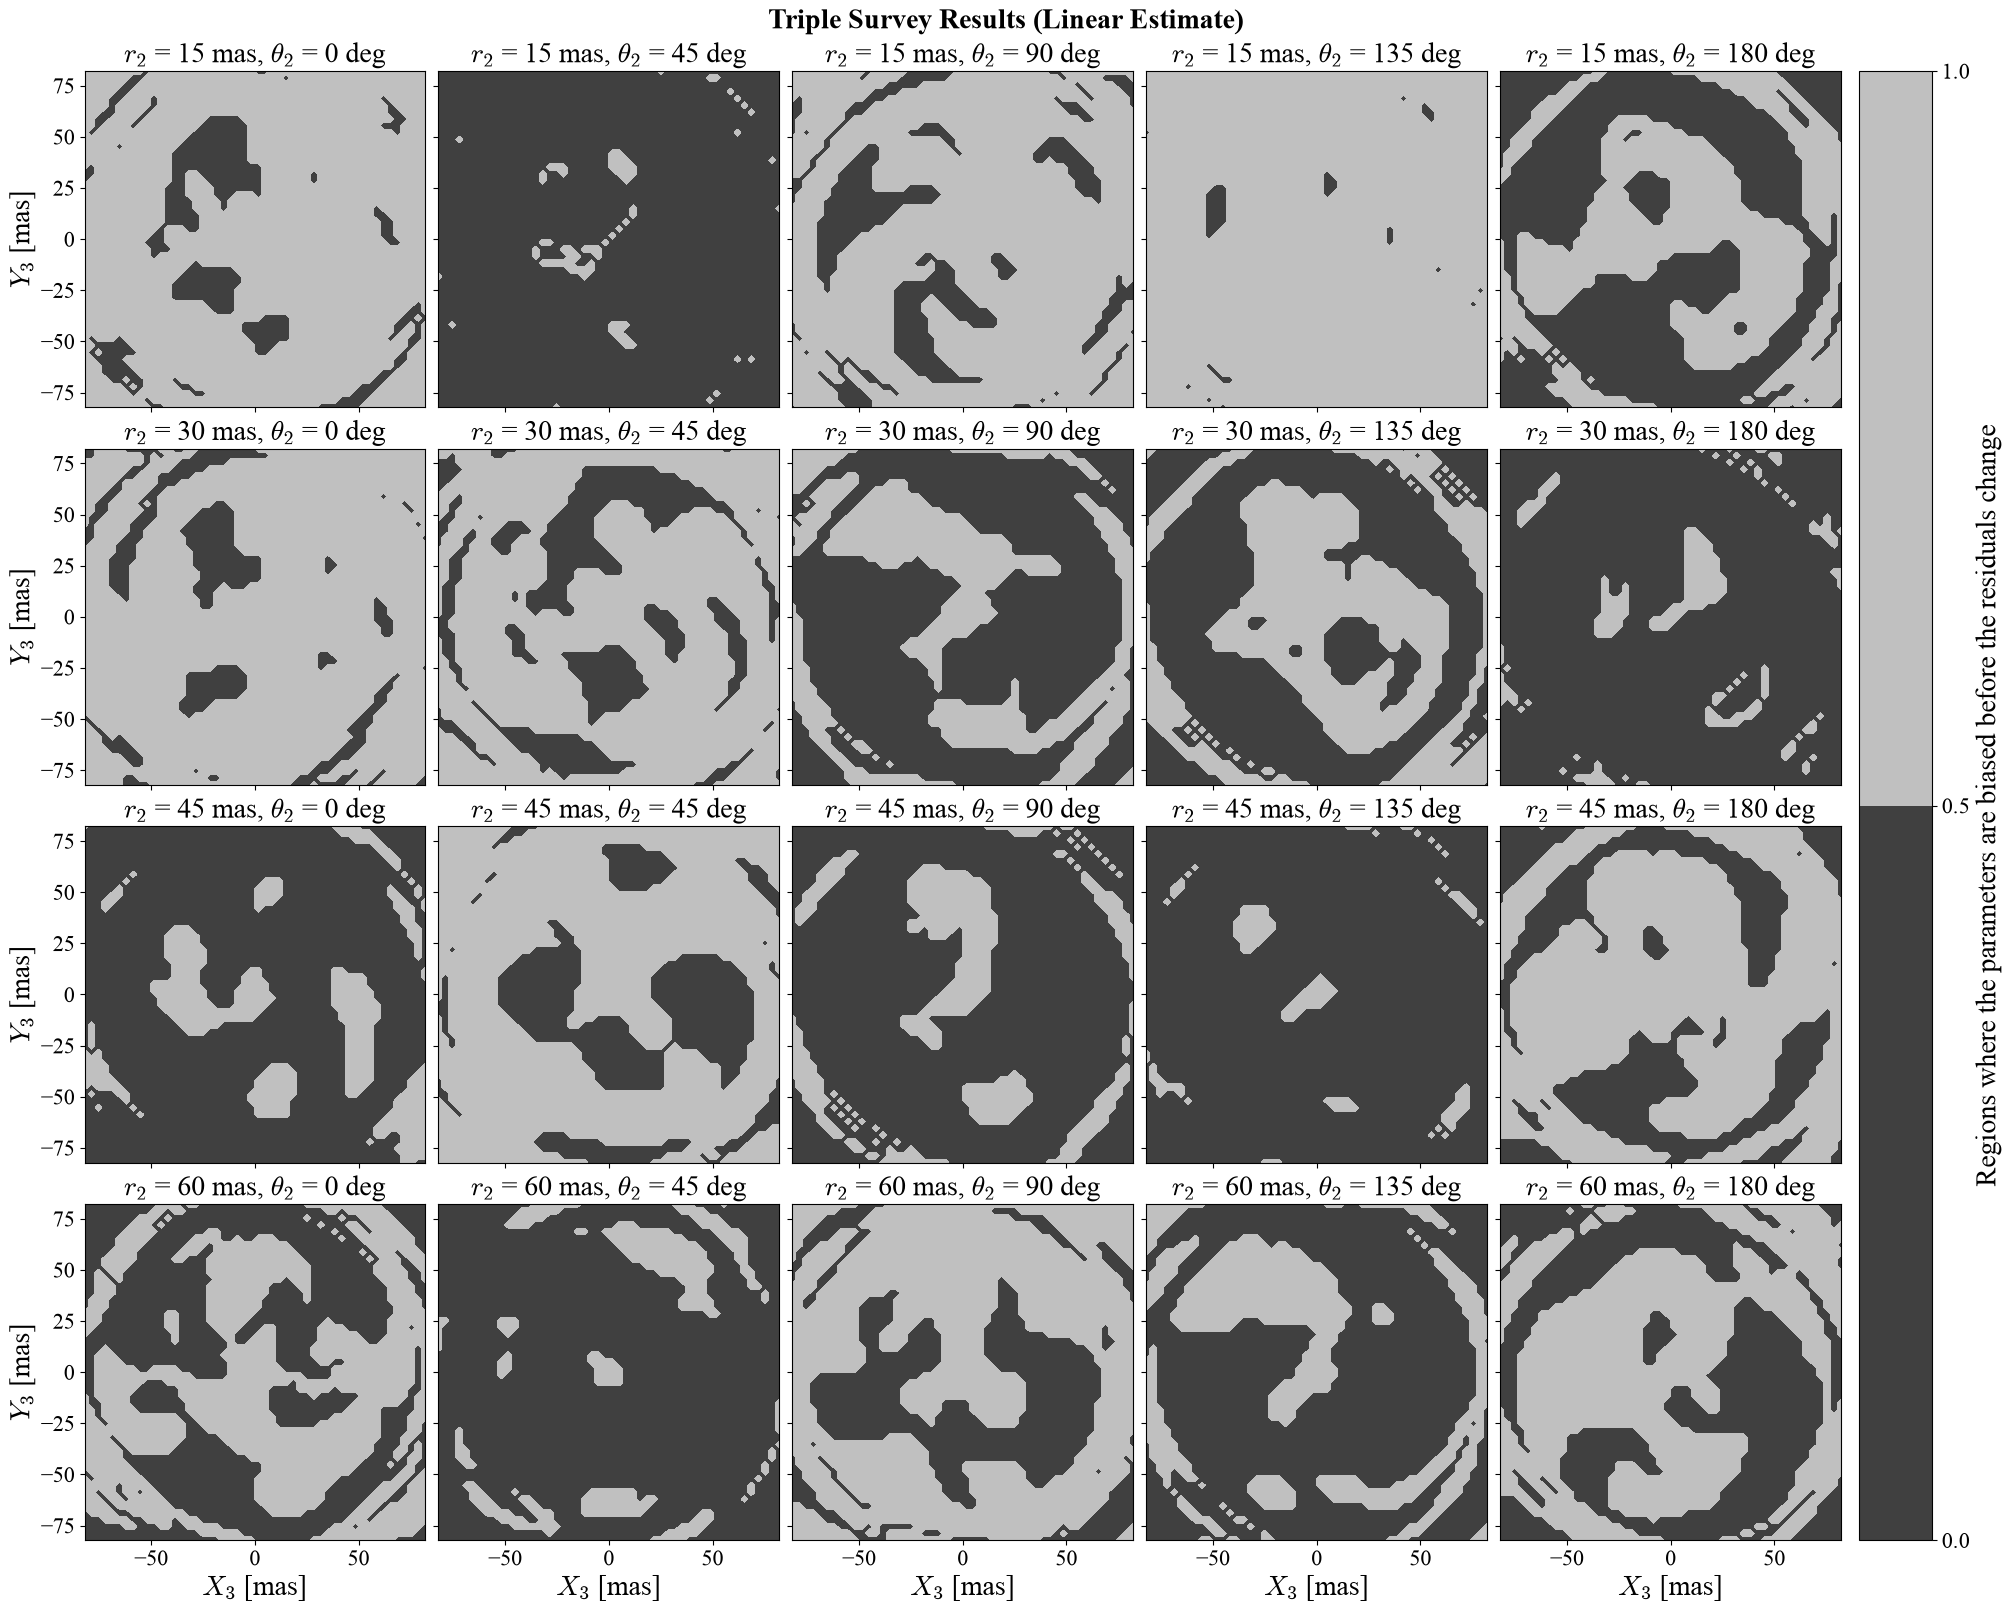

In [61]:
fig = plt.figure(figsize=(20, 16))
fig.set_constrained_layout(True)
axes = fig.subplots(4, 5, sharex=True, sharey=True)

fig.suptitle('Triple Survey Results (Linear Estimate)')

biased_region = F3_detect > F3_crit

for i, r2 in enumerate(r2s):
    for j, theta2 in enumerate(theta2s):
        ax = axes[i, j]

        ax.set_title(f'$r_2$ = {r2} mas, $\\theta_2$ = {theta2} deg')

        img = ax.contourf(biased_region[i, j], cmap='grey', origin='lower', extent=[x3s.min(), x3s.max(), y3s.min(), y3s.max()], vmin=0, vmax=1)
        
        if j == 0:
            ax.set_ylabel('$Y_3$ [mas]')
        if i == 3:
            ax.set_xlabel('$X_3$ [mas]')

fig.colorbar(img, ax=axes, location='right', label=r'Regions where the parameters are biased before the residuals change', pad=0.01)

plt.show()